# GIF temporal: a mesma banda nas diferentes imagens

O eixo da animação é a **data da observação**. A banda 99 (4,851–4,893 µm; centro 4,873 µm) fica fixa. Cada frame vem de uma exposição diferente do campo WiseView (RA 133,786245°, Dec −7,244372°). A tabela de canais do cubo define a banda; os pixels vêm das exposições deste campo.

Nos 40 FITS locais, três imagens têm pixels válidos nessa banda. A cobertura é parcial, sobretudo na terceira imagem (cerca de 10% do campo), e aparece no título. Azul indica ausência de cobertura e não uma fonte desaparecendo. A escala de brilho é fixa.

Execute `uv run --extra viz spherex-tracking temporal-band` para refazer. A animação espectral anterior foi uma interpretação incorreta do pedido e permanece apenas como produto auxiliar.

In [ ]:
from pathlib import Path
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "outputs").exists():
    ROOT = ROOT.parent
display(Image(filename=str(ROOT / "outputs/temporal_band/spherex_fixed_band_observations.gif")))

# Animação SPHEREx em períodos de seis meses

Este GIF usa o ponto indicado no link WiseView: **RA 133.786245°, Dec −7.244372°**. A busca encontrou imagens SPHEREx públicas entre maio de 2025 e maio de 2026, cobrindo dois períodos completos de seis meses.

O parâmetro WiseView `size=176` é o campo de visão de **176 segundos de arco**. Como um pixel SPHEREx cobre cerca de 6,2 segundos de arco, o recorte tem aproximadamente 28 pixels nativos por lado. O GIF amplia a imagem para exibição; isso não cria resolução nova.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display
from astropy.table import Table

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "outputs/timelapse"
report = json.loads((OUT / "timelapse_report.json").read_text())
print("Imagens SPHEREx D6 baixadas:", report["n_downloaded"])
print("Períodos completos de seis meses:", report["complete_half_year_count"])
print("Exposições na faixa espectral comparável:", report["n_wavelength_matched"])
print("Visitas exibidas no GIF:", report["n_visits"])
print("Todos os FITS, inclusive os fora do GIF, estão em data/timelapse_fov176as/.")
print("Faixa central escolhida: {:.3f} µm ± {:.2f} µm".format(
    report["wavelength_filter"]["center_um"], report["wavelength_filter"]["tolerance_um"]
))
print("A referência usa WISE W2 (~4,6 µm). O primeiro semestre SPHEREx não tem cobertura nessa faixa; por isso foi escolhida a faixa comum mais próxima que cobre todos os períodos.")
print("Campo: {} arcsec; grade: {}×{} pixels nativos.".format(
    report["output_pixel_grid"]["field_of_view_arcsec"],
    report["output_pixel_grid"]["size_pixels"], report["output_pixel_grid"]["size_pixels"]
))


Imagens SPHEREx D6 baixadas: 40
Períodos completos de seis meses: 2
Exposições na faixa espectral comparável: 15
Visitas exibidas no GIF: 3
Todos os FITS, inclusive os fora do GIF, estão em data/timelapse_fov176as/.
Faixa central escolhida: 4.885 µm ± 0.12 µm
A referência usa WISE W2 (~4,6 µm). O primeiro semestre SPHEREx não tem cobertura nessa faixa; por isso foi escolhida a faixa comum mais próxima que cobre todos os períodos.
Campo: 176 arcsec; grade: 28×28 pixels nativos.


In [2]:
display(Table(rows=[{
    "frame": f["frame"],
    "datas": f["date_start"][:10] + " a " + f["date_end"][:10],
    "exposicoes_combinadas": f["n_images"],
    "comprimento_de_onda_um": round(f["mean_wavelength_um"], 3),
} for f in report["frame_records"]]))

frame,datas,exposicoes_combinadas,comprimento_de_onda_um
int64,str23,int64,float64
1,2025-05-05 a 2025-05-05,3,4.944
2,2025-11-14 a 2025-11-14,7,4.874
3,2026-04-26 a 2026-04-30,5,4.853


In [3]:
from astropy.table import Table

print("Os 40 FITS baixados estão em:", ROOT / "data/timelapse_fov176as")
print("15 entram no GIF; 25 foram deixados fora por terem comprimento de onda diferente.")
print("A busca retornou 45 produtos D6; 5 ficaram fora porque estão além dos dois períodos completos usados.")
print("Inventário dos 40 arquivos:", OUT / "observations.csv")
excluded = [o for o in report["observations"] if not o["included_in_gif"]]
display(Table(rows=[{
    "obs_id": o["obs_id"],
    "data": o["date"][:10],
    "lambda_um": round(o["target_wavelength_um"], 3),
    "arquivo": Path(o["path"]).name,
} for o in excluded]))

Os 40 FITS baixados estão em: /home/tatiana/Transferências/projetos/nasaSpaceApps/data/timelapse_fov176as
15 entram no GIF; 25 foram deixados fora por terem comprimento de onda diferente.
A busca retornou 45 produtos D6; 5 ficaram fora porque estão além dos dois períodos completos usados.
Inventário dos 40 arquivos: /home/tatiana/Transferências/projetos/nasaSpaceApps/outputs/timelapse/observations.csv


obs_id,data,lambda_um,arquivo
str17,str10,float64,str22
2025W46_1A_0075_4,2025-11-10,4.417,2025W46_1A_0075_4.fits
2025W46_1A_0076_1,2025-11-10,4.448,2025W46_1A_0076_1.fits
2025W46_1A_0076_2,2025-11-10,4.48,2025W46_1A_0076_2.fits
2025W46_1A_0076_3,2025-11-10,4.513,2025W46_1A_0076_3.fits
2025W46_1A_0090_1,2025-11-10,4.545,2025W46_1A_0090_1.fits
2025W46_1A_0090_2,2025-11-10,4.578,2025W46_1A_0090_2.fits
2025W46_1A_0090_3,2025-11-10,4.612,2025W46_1A_0090_3.fits
2025W46_1A_0238_1,2025-11-10,4.632,2025W46_1A_0238_1.fits
2025W46_1A_0238_2,2025-11-10,4.666,2025W46_1A_0238_2.fits


## GIF

Cada frame combina as imagens daquela visita. As estrelas devem permanecer aproximadamente no mesmo lugar porque os recortes foram reprojetados para uma grade celeste fixa. Variações pequenas de brilho ou forma ainda podem vir da resposta instrumental e da diferença entre exposições.

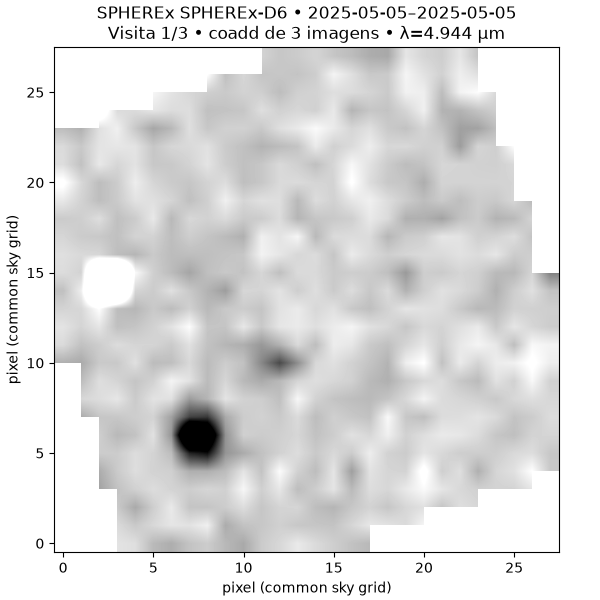

In [4]:
display(Image(filename=str(OUT / "spherex_wiseview.gif")))

## Frames lado a lado

O contraste é fixo entre os frames, como no modo linear do WiseView. A ampliação de exibição ajuda a ver os pixels nativos; ela não equivale a uma imagem SPHEREx de 64×64 pixels.

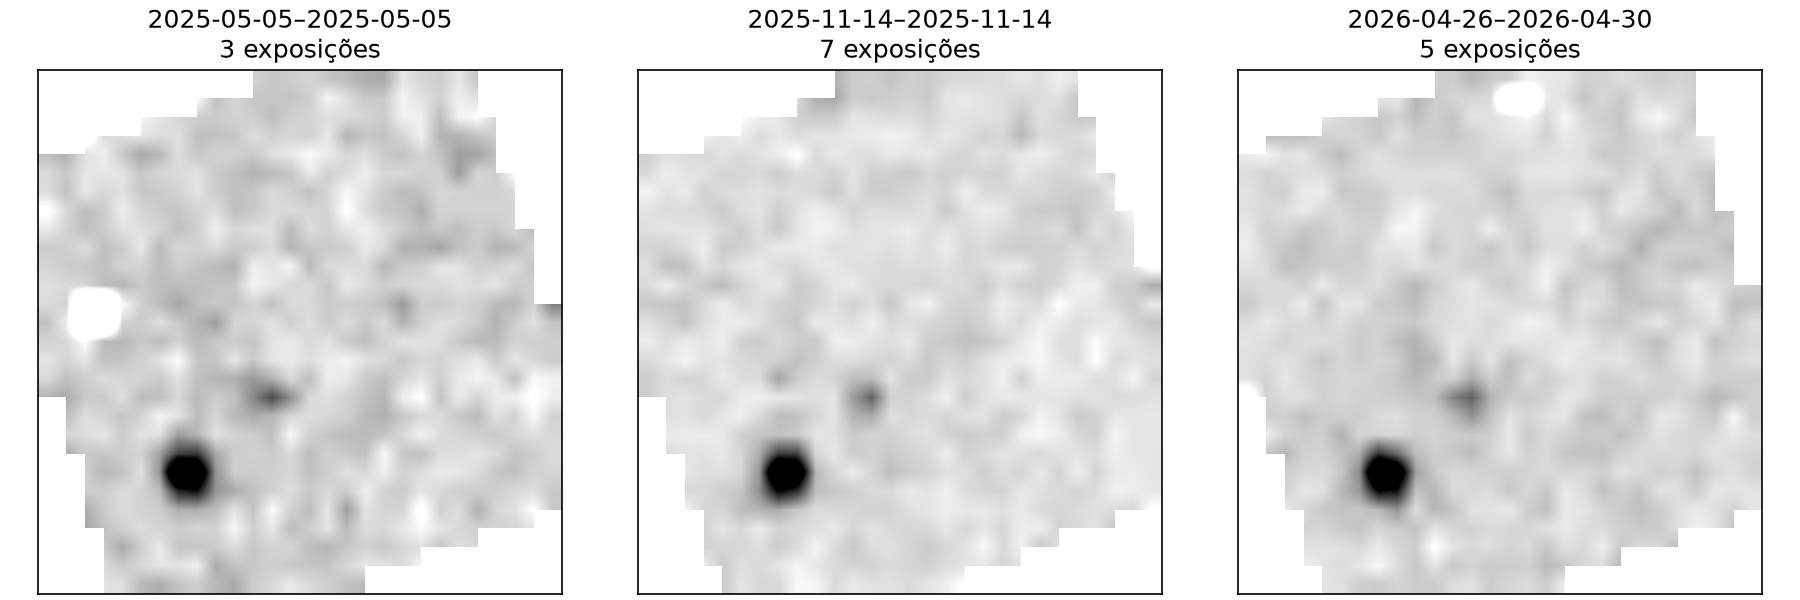

In [5]:
display(Image(filename=str(OUT / "spherex_wiseview_frames.png")))

## Reproduzir

```bash
uv run spherex-tracking timelapse
```

Os FITS e o resultado da consulta ficam em `data/timelapse_fov176as/`. O inventário de épocas, comprimentos de onda e URLs está em `outputs/timelapse/timelapse_report.json`.

## Animação Gaia DR3

Este GIF usa as 10 fontes Gaia DR3 de magnitude G<20 dentro do mesmo campo de 176 segundos de arco. Ele propaga as posições catalogadas usando o movimento próprio medido, entre 25/07/2014 e 28/05/2017. **São posições previstas pelo catálogo, não imagens Gaia por época.** O painel direito amplia a trajetória angular real da fonte com maior movimento próprio.

Fontes Gaia no campo: 10
Intervalo Gaia DR3: {'start': '2014-07-25', 'end': '2017-05-28', 'months': 34}
Maior deslocamento previsto: 0.050 arcsec


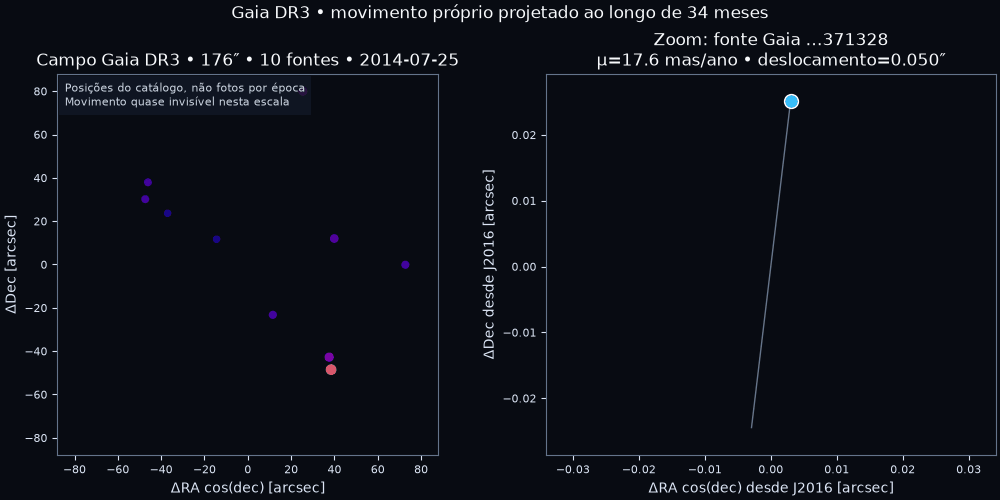

In [6]:
GAIA_OUT = ROOT / "outputs/gaia_timelapse"
gaia_report = json.loads((GAIA_OUT / "gaia_timelapse_report.json").read_text())
print("Fontes Gaia no campo:", gaia_report["n_sources"])
print("Intervalo Gaia DR3:", gaia_report["gaia_dr3_observation_span"])
print("Maior deslocamento previsto:", f"{gaia_report['fastest_displacement_arcsec_over_span']:.3f} arcsec")
display(Image(filename=str(GAIA_OUT / "gaia_dr3_motion.gif")))